# El protocolo del propio artículo: el ajuste de la Tabla 5 juzgado con los muestreos a los que se ajustó

**Pregunta:** ¿Qué dice del modelo del HP500 el protocolo dentro de la muestra del estado del arte, un ajuste juzgado con los mismos diez muestreos, y separa la física de un ajuste sin restricciones?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los notebooks 01 y 02 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook usted puede:

- decir cuál es el estado del arte sobre este chancador, y qué protocolo usa para juzgar su propio modelo;
- correr ese protocolo en los diez muestreos con el código CrusherCal del pipeline, dentro de la muestra;
- comparar tres modelos dentro de la muestra, la física calibrada, la misma física con sus escalares reajustados y una regresión sin restricciones;
- leer un coeficiente ajustado por su sentido físico, y decir por qué un buen número dentro de la muestra no puede decidir entre los modelos.

## Preparación

Numpy y matplotlib. Las funciones de CrusherCal vienen de la carpeta `hp500` del pipeline, que solo necesita numpy.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

La celda importa el lector de muestreos, el constructor de la columna vertebral y el constructor de CrusherCal.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo
from pipeline.model.crusher.capacity import throughput, HP500_QREF
from pipeline.model.crusher.hp500 import HP500_NOMINAL
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos y los dos documentos versionados derivados de ellos. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv`; `data/derived/hp500/backbone.json`, los resultados del motor en los muestreos; y `data/derived/hp500/loo.json`, el documento de CrusherCal (contrato `hp500-loo`), que aquí solo se usa para comprobar que la corrida viva lo devuelve.

La celda lee los tres archivos.

In [2]:
# Lea los muestreos y los dos documentos versionados
surveys = read_surveys().accepted
derived = ROOT / "data" / "derived" / "hp500"
committed_backbone = json.loads((derived / "backbone.json").read_text(encoding="utf-8"))
committed_loo = json.loads((derived / "loo.json").read_text(encoding="utf-8"))
print("muestreos:", len(surveys), "| versión del motor:", committed_backbone["engine_version"])

muestreos: 10 | versión del motor: 0.09.003


## Método

**El lado del producto.** La columna vertebral calibrada es la vía calibrada del motor (notebook 02) con sus constantes publicadas: la base de capacidad $Q_T \approx 647$ t/h y la forma de potencia $P_c = 1{,}30\,P_d + 110$ kW. El código CrusherCal del pipeline toma el documento de columna vertebral y evalúa modelos de él con los mismos datos medidos. La celda reconstruye ambos documentos en vivo, desde los muestreos, y comprueba que son los versionados, de modo que todo lo de abajo se calcula aquí y no se lee.

In [3]:
# Reconstruya en vivo la columna vertebral y los documentos de CrusherCal y compárelos con los versionados
version = committed_backbone["engine_version"]
live_backbone = backbone.build(surveys, version)
live_loo = loo.build(live_backbone, version)
print("la columna vertebral es igual a la versionada:", live_backbone == committed_backbone, "| CrusherCal es igual al versionado:", live_loo == committed_loo)

la columna vertebral es igual a la versionada: True | CrusherCal es igual al versionado: True


Los ajustes propios del protocolo son constantes de módulo del código CrusherCal: la semilla del control de barajado, la penalización ridge del modelo de residuo y el recorte que acota el residuo a una fracción del valor de la columna vertebral. La celda las imprime, porque definen qué es «M1» más abajo.

In [4]:
# Las constantes del protocolo CrusherCal
print("semilla del control de barajado:", loo.SEED, "| penalización ridge:", loo.RIDGE_LAMBDA, "| recorte del residuo, fracción de la columna vertebral:", loo.RESID_CLIP_FRAC)

semilla del control de barajado: 42 | penalización ridge: 1.0 | recorte del residuo, fracción de la columna vertebral: 0.2


## Estado del arte

**La fuente.** El estado del arte sobre esta máquina es Rocha, Campos, Silva y Tavares (2024; https://doi.org/10.3390/min14090919): un modelo a medida del HP500, con los parámetros de clasificación y de quiebre de Andersen-Whiten, la capacidad y la potencia, ajustado a los diez muestreos y juzgado con ellos. Su protocolo es el usual para esos modelos, un ajuste dentro de la muestra: las constantes vienen de los diez muestreos, y la coincidencia del modelo con los mismos diez muestreos es la evidencia. La literatura vecina sobre sustitutos aprendidos de modelos de conminución tiene la misma forma: Koh et al. (2021; https://doi.org/10.1016/j.mineng.2021.107026) juzgan una red frente al modelo que emula, no frente a una planta retenida.

Un ajuste dentro de la muestra no es erróneo; responde una pregunta distinta de «cómo le irá en el próximo muestreo». El notebook corre ese protocolo con el propio código CrusherCal del pipeline y lee lo que puede decir. El documento de CrusherCal contiene, para cada modelo, un bloque calculado con el ajuste en los diez muestreos (`leaky`, la variante dentro de la muestra) y un bloque con el muestreo retenido (`strict`, tema 06). La celda lee los bloques de tonelaje dentro de la muestra de tres modelos: la columna vertebral calibrada con el escalar $Q_T$ reajustado a los diez muestreos (M0), la misma columna con un residuo ridge acotado (M1), y una regresión lineal sin restricciones sobre la abertura y el f80 sin física (M2), junto a una línea base de media constante.

In [5]:
# Errores de tonelaje dentro de la muestra (leaky) de los tres modelos, la columna vertebral entregada y la media constante
block = live_loo["loo"]["tph"]["leaky"]
shipped = live_loo["tph_parity"]["backbone"]
rows = {
    "columna vertebral entregada (QT = 647 t/h)": shipped["mape_pct"],
    "M0, QT reajustado a los diez": block["M0_backbone"]["mape_pct"],
    "M1, columna vertebral más residuo acotado": block["M1_residual"]["mape_pct"],
    "M2, regresión sin restricciones": block["M2_freeform"]["mape_pct"],
    "media constante": block["constant_mean"]["mape_pct"],
}
for name, value in rows.items():
    print(f"{name:42s} MAPE dentro de la muestra {value:6.2f} %")

columna vertebral entregada (QT = 647 t/h) MAPE dentro de la muestra  11.55 %
M0, QT reajustado a los diez               MAPE dentro de la muestra  10.95 %
M1, columna vertebral más residuo acotado  MAPE dentro de la muestra   8.51 %
M2, regresión sin restricciones            MAPE dentro de la muestra   8.24 %
media constante                            MAPE dentro de la muestra  16.46 %


La figura dibuja los cinco números. Leídos como los lee el estado del arte, la historia es favorable: la columna vertebral calibrada entregada queda dentro de la banda de 15 por ciento que registra la ficha de este protocolo, y supera a la media constante. Pero la barra que gana es la regresión sin restricciones, con el modelo sin física en el error más bajo, y el modelo con residuo también supera a la columna vertebral. Dentro de la muestra, agregar parámetros libres siempre ayuda.

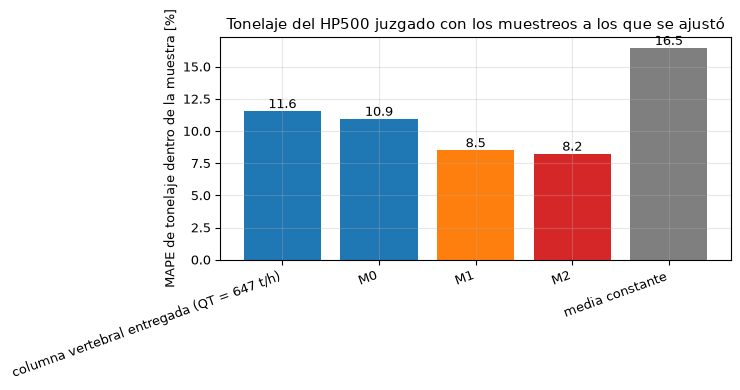

In [6]:
# Gráfico de barras del error de tonelaje dentro de la muestra de los cinco modelos
labels = [name.split(",")[0] for name in rows]
fig, ax = plt.subplots()
bars = ax.bar(range(len(rows)), list(rows.values()), color=["tab:blue", "tab:blue", "tab:orange", "tab:red", "tab:grey"])
ax.bar_label(bars, fmt="%.1f")
ax.set_xticks(range(len(rows)), labels, rotation=20, ha="right")
ax.set_ylabel("MAPE de tonelaje dentro de la muestra [%]")
ax.set_title("Tonelaje del HP500 juzgado con los muestreos a los que se ajustó")
fig.tight_layout()
plt.show()

El orden de las barras es el orden del número de parámetros libres, no de la calidad de la física: la regresión sin física supera al modelo calibrado, lo que no puede ser lo que un modelador quiere concluir. La figura dice que un número dentro de la muestra no puede ordenar estos modelos, y no dice cuánto mejor o peor lo haría la física con un muestreo nuevo. La potencia lo muestra con más fuerza, que es la celda siguiente: reajusta la forma de potencia del artículo al consumo de Bond en los diez muestreos y lee los coeficientes.

In [7]:
# La forma de potencia del artículo reajustada dentro de la muestra al consumo de Bond: sus coeficientes y los errores de las estimaciones de potencia
parity = live_loo["power_parity"]
refit = parity["refit_pc"]
print("forma reajustada Pc = zeta Pd + Pn: zeta =", refit["zeta"], "| Pn =", refit["pn"], "kW")
print("las constantes del artículo: zeta = 1,30, Pn = 110 kW")
for name, key in (("consumo de Bond puro", "bare_bond"), ("forma del artículo sobre el consumo de Bond", "engine_pc_1p30_110"), ("forma reajustada dentro de la muestra", "refit_pc"), ("media constante", "constant_mean")):
    print(f"{name:44s} MAPE {parity[key]['mape_pct']:6.2f} %   R2 {parity[key]['r2']:7.3f}")

forma reajustada Pc = zeta Pd + Pn: zeta = -2.4146 | Pn = 828.6 kW
las constantes del artículo: zeta = 1,30, Pn = 110 kW
consumo de Bond puro                         MAPE  26.88 %   R2  -1.286
forma del artículo sobre el consumo de Bond  MAPE  47.58 %   R2  -3.643
forma reajustada dentro de la muestra        MAPE  19.28 %   R2   0.205
media constante                              MAPE  22.03 %   R2   0.000


El coeficiente reajustado es $\zeta = -2{,}41$ con un desfase de 828,6 kW: el óptimo dentro de la muestra de la forma es una recta de pendiente negativa, en que más potencia de Bond predice menos potencia medida. El error de 19,28 por ciento del ajuste supera a las constantes del artículo en este conjunto (47,58 por ciento) y al consumo de Bond puro (26,88 por ciento), y es un número que un informe podría citar. También es un absurdo físico, una eficiencia negativa. Surge porque el consumo de Bond varía poco (196 a 237 kW) frente a una potencia medida que abarca de 187 a 355 kW y que tiene correlación negativa con él, de modo que la regresión debe inclinar su recta hacia abajo para seguir la dispersión medida: ajusta la variación entre muestreos, no la física. La figura grafica la potencia medida contra el consumo de Bond con esa recta.

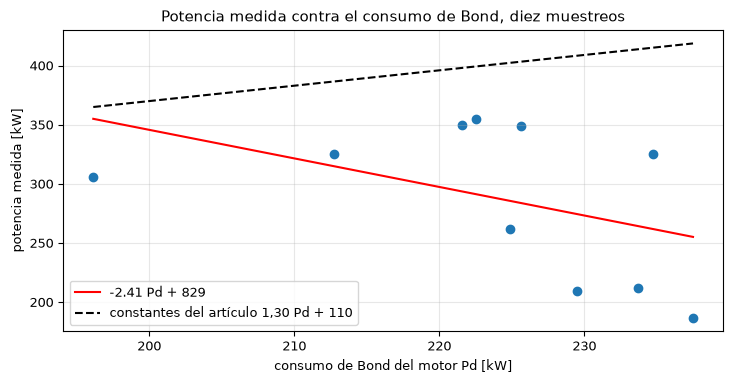

correlación de la potencia medida con el consumo de Bond: -0.453


In [8]:
# Dispersión de la potencia medida contra el consumo de Bond con la recta del reajuste dentro de la muestra
bond = np.array([s["backbone"]["bond_power_kw"] for s in live_backbone["surveys"]])
measured_kw = np.array([s["measured"]["power_kw"] for s in live_backbone["surveys"]])
fig, ax = plt.subplots()
ax.scatter(bond, measured_kw)
line = np.linspace(bond.min(), bond.max(), 20)
ax.plot(line, refit["zeta"] * line + refit["pn"], "r-", label=f"{refit['zeta']:.2f} Pd + {refit['pn']:.0f}")
ax.plot(line, 1.30 * line + 110, "k--", label="constantes del artículo 1,30 Pd + 110")
ax.set_xlabel("consumo de Bond del motor Pd [kW]")
ax.set_ylabel("potencia medida [kW]")
ax.set_title("Potencia medida contra el consumo de Bond, diez muestreos")
ax.legend()
fig.tight_layout()
plt.show()
print("correlación de la potencia medida con el consumo de Bond:", round(float(np.corrcoef(bond, measured_kw)[0, 1]), 3))

Los diez puntos forman una nube sin una relación clara: la recta roja se inclina hacia abajo entre ellos, la recta negra punteada de las constantes del artículo queda sobre todos, y la correlación impresa bajo la figura es negativa. La figura muestra por qué no se puede confiar en que un ajuste dentro de la muestra lleve sentido físico con diez puntos y un regresor plano, y por qué el informe del producto mantiene la potencia medida como referencia y no ofrece los kW del modelo como una predicción. No muestra qué pasa con un muestreo fuera de los diez; para eso hace falta el protocolo con datos retenidos del tema 06.

**¿Qué números dentro de la muestra dependen del azar?** Cuatro de los cinco números de tonelaje son deterministas dados los muestreos. El control de barajado es la excepción, porque permuta los valores medidos con un generador con semilla. La celda reconstruye el documento de CrusherCal con otra semilla y compara los números dentro de la muestra de los modelos con los de la semilla versionada.

In [9]:
# Reconstruya CrusherCal con la semilla 1 y compare los errores de tonelaje dentro de la muestra con la semilla versionada
other = loo.build(live_backbone, version, seed=1)["loo"]["tph"]["leaky"]
for name in ("M0_backbone", "M1_residual", "M2_freeform", "constant_mean", "M1_label_shuffle"):
    print(f"{name:18s} seed {loo.SEED}: {block[name]['mape_pct']:6.2f} %   seed 1: {other[name]['mape_pct']:6.2f} %")

M0_backbone        seed 42:  10.95 %   seed 1:  10.95 %
M1_residual        seed 42:   8.51 %   seed 1:   8.51 %
M2_freeform        seed 42:   8.24 %   seed 1:   8.24 %
constant_mean      seed 42:  16.46 %   seed 1:  16.46 %
M1_label_shuffle   seed 42:  21.18 %   seed 1:  14.71 %


Los cuatro modelos no se mueven: sus números dentro de la muestra pertenecen a los datos y no a la semilla. Solo cambia el control de barajado, de 21,18 a 14,71 por ciento, y esa dispersión es información en sí misma: un control construido para ser peor que la física a veces resulta en 14,71 por ciento, cerca de los modelos a los que debe perder, lo que advierte que con diez puntos un solo sorteo del control dice poco. La celda siguiente pasa al escalar libre de la propia física, la base de capacidad.

In [10]:
# Reajuste la base de capacidad QT de la columna vertebral a los diez muestreos por mínimos cuadrados y compárela con la del artículo
shape = np.array([throughput("cone-sec", s.css_mm, HP500_NOMINAL.throw_mm, HP500_NOMINAL.speed_rpm, True) for s in surveys]) / HP500_QREF
measured = np.array([s.feed_tph for s in surveys])
qt_refit = float((shape * measured).sum() / (shape * shape).sum())
print("base de capacidad del artículo [t/h]:", HP500_QREF, "| óptimo de mínimos cuadrados dentro de la muestra [t/h]:", round(qt_refit, 1))

base de capacidad del artículo [t/h]: 647 | óptimo de mínimos cuadrados dentro de la muestra [t/h]: 686.0


El óptimo dentro de la muestra del escalar es 686,0 t/h, 6 por ciento sobre los 647 t/h del artículo, y compra la reducción del error de 11,55 a 10,95 por ciento. El valor del artículo no es el de mínimos cuadrados con estas diez filas: es la constante publicada, y la diferencia muestra cuánto mueve el número un solo escalar dentro de la muestra, 0,6 puntos. La regresión sin restricciones con sus tres coeficientes libres lo mueve en 3,3 puntos, que es el costo en grados de libertad del orden dentro de la muestra.

## Resultados

**Respuesta:** el protocolo dentro de la muestra es favorable al modelo del HP500 y no puede distinguirlo de un sobreajuste. En tonelaje los errores dentro de la muestra son 11,55 por ciento para la columna vertebral entregada, 10,95 para el escalar reajustado, 8,51 para el residuo acotado, 8,24 para la regresión sin restricciones y 16,46 para la media constante: el orden sigue el número de parámetros libres, y la regresión sin física tiene el error más bajo. En potencia el reajuste de la forma del artículo dentro de la muestra da 19,28 por ciento, mejor que las constantes del artículo (47,58 por ciento) y que el consumo de Bond puro (26,88 por ciento), con un coeficiente negativo, zeta = -2,41, sin sentido físico.

La primera figura muestra el orden por número de parámetros, la segunda el coeficiente absurdo sobre una nube sin relación. Un validador concluiría que el protocolo del estado del arte es sólido para lo que afirma, una calibración, y mudo sobre lo que el producto quiere afirmar, una predicción; que la regresión sin física ganando dentro de la muestra es la evidencia de que el protocolo no puede discriminar; y que el paso siguiente correcto es retener cada muestreo por turno, lo que el tema 06 hace con el mismo código.

## Resumen

El estado del arte de este chancador ajusta diez muestreos y juzga el ajuste con los mismos diez, un protocolo que favorece al modelo con más libertad: aquí la regresión sin física y un coeficiente de potencia con el signo equivocado. El código CrusherCal del pipeline corre el protocolo y entrega los números dentro de la muestra junto a los retenidos en un solo documento. El tema 06 lee la mitad retenida, que es donde está la afirmación propia del producto.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193, 484-494. https://onemine.org/documents/the-third-theory-of-comminution
- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026